# 02 · Results: how well can we forecast fires 1–7 days ahead?

Every model forecasts, for each ~11 km land cell in Sumatra and Kalimantan, the probability that a fire is detected there on each of the next 7 days.

* **Train** 2012–2020 · **validation** 2021–2022 (early stopping, calibration, model choice) · **test** 2023 to October 2026. The test period was not used for any decision, and it includes two El Niño fire seasons, 2023 and 2026.
* **Models:** two simple baselines (*climatology*: the cell's historical fire rate for that month; *persistence*: carry today's fire state forward), **LightGBM** on 42 per-cell features, a **U-Net ensemble** (3 regularised variants), and the **final model**: the average of the U-Net ensemble and LightGBM. It was chosen *before* looking at the test set, as the best mean validation PR-AUC over day 1 and day 7.
* **Metrics:** PR-AUC (average precision), where random guessing scores the fire rate (~1.3% of cells per day), so we also show it as ×-better-than-random. *Top-5% coverage* is the share of fires that fall in each day's 5% riskiest cells, i.e. where patrols would go. *New ignitions* are fires in cells with no fire in the previous 14 days: the hard, useful part, because persistence cannot predict them.

Inputs: run `titikapi evaluate-baselines`, `train-lgbm`, `evaluate-model` and `evaluate-ensemble` first (see `scripts/kaggle_build.py`), which write `reports/` and `models/<name>/probs_*.npy`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from titikapi import viz
from titikapi.config import ROOT, SPLITS
from titikapi.data.cube import load_fire_matrix, recent_fire
from titikapi.data.static import load_provinces
from titikapi.grid import Grid
from titikapi.models.baselines import Climatology, Persistence
from titikapi.models.dataset import ARRAYS_DIR, Arrays
from titikapi.models.evaluate import issue_days
from titikapi.models.metrics import average_precision, topk_coverage
from titikapi.models.train import MODELS_DIR

viz.use_style()
FIG = ROOT / 'docs' / 'figures'
res = pd.read_csv(ROOT / 'reports' / 'comparison.csv')
test = res[res.split == 'test']
a = Arrays.load(ARRAYS_DIR)
idx = np.load(MODELS_DIR / 'ens_mix' / 'idx_test.npy')
print(f'test: {len(idx)} issue days, {a.time[idx[0]].date()} .. {a.time[idx[-1]].date()}')

NAMES = {'ens_mix': 'Final model', 'ens_unet': 'U-Net ensemble', 'lgbm': 'LightGBM',
         'persistence': 'Persistence', 'climatology': 'Climatology'}
# colour follows the model in every chart; baselines are grey context
STYLE = {'ens_mix': (viz.SERIES[0], '-'), 'ens_unet': (viz.SERIES[1], '-'),
         'lgbm': (viz.SERIES[2], '-'), 'persistence': (viz.INK_2, '--'),
         'climatology': (viz.MUTED, ':')}

test: 1393 issue days, 2023-01-01 .. 2026-10-24


## Headline numbers (test period)

In [2]:
rows = []
for m in ['climatology', 'persistence', 'lgbm', 'ens_unet', 'ens_mix']:
    r = test[test.model == m].set_index(['slice', 'lead'])
    rows.append({
        'model': NAMES[m],
        'PR-AUC day 1': r.loc[('all', 1), 'ap'],
        '× random': r.loc[('all', 1), 'ap'] / r.loc[('all', 1), 'base_rate'],
        'PR-AUC day 7': r.loc[('all', 7), 'ap'],
        'top-5% catches, day 1': r.loc[('all', 1), 'top5_coverage'],
        'new fires: top-5% catches, day 1': r.loc[('new_ignition', 1), 'top5_coverage'],
        'new fires: top-5% catches, day 7': r.loc[('new_ignition', 7), 'top5_coverage'],
        'Brier day 1': r.loc[('all', 1), 'brier'],
    })
headline = pd.DataFrame(rows).set_index('model')
headline.style.format({c: '{:.1%}' for c in headline.columns if 'catches' in c}).format({'PR-AUC day 1': '{:.3f}', 'PR-AUC day 7': '{:.3f}', '× random': '{:.0f}×', 'Brier day 1': '{:.4f}'})

,PR-AUC day 1,× random,PR-AUC day 7,"top-5% catches, day 1","new fires: top-5% catches, day 1","new fires: top-5% catches, day 7",Brier day 1
model,,,,,,,
Climatology,0.113,9×,0.113,0.252638,0.118411,0.139442,0.0122
Persistence,0.259,20×,0.170,0.370308,0.022418,0.027367,0.0113
LightGBM,0.359,28×,0.232,0.419106,0.139465,0.117484,0.0107
U-Net ensemble,0.358,27×,0.247,0.419468,0.147918,0.143312,0.0102
Final model,0.365,28×,0.244,0.425116,0.148513,0.132831,0.0101


## 1 · Skill by lead day

All models lose skill as the horizon grows, but the gap to persistence stays wide. LightGBM matches the U-Net on day 1; from day 2 on, the U-Net ensemble is consistently ahead. The final model (their average) is best on day 1 and close to the U-Net after.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


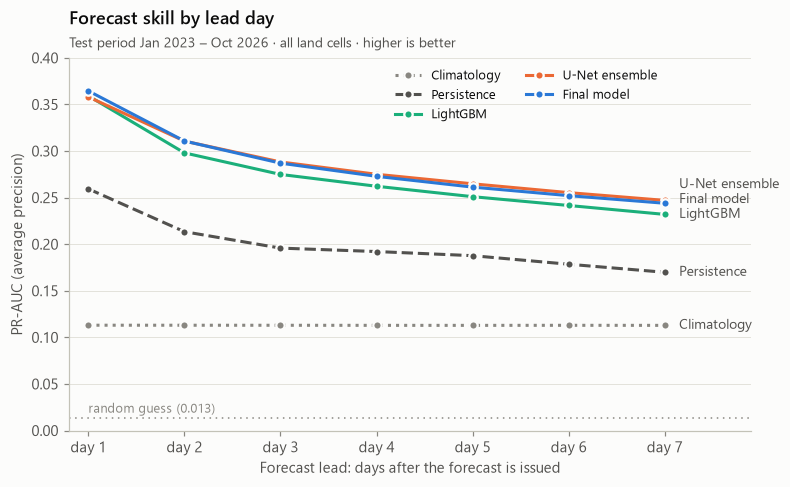

In [3]:
leads = np.arange(1, 8)
def curve(model, slice_='all', metric='ap'):
    d = test[(test.model == model) & (test['slice'] == slice_)].sort_values('lead')
    return d[metric].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.4))
ends = []
for m in ['climatology', 'persistence', 'lgbm', 'ens_unet', 'ens_mix']:
    color, ls = STYLE[m]
    y = curve(m)
    ax.plot(leads, y, color=color, ls=ls, marker='o', ms=5.5,
            mec=viz.SURFACE, mew=1.5, label=NAMES[m])
    ends.append((y[-1], NAMES[m]))
base = test[(test.model == 'ens_mix') & (test['slice'] == 'all')].base_rate.mean()
ax.axhline(base, color=viz.MUTED, lw=1, ls=(0, (1, 3)))
ax.text(1, base + 0.006, f'random guess ({base:.3f})', color=viz.MUTED, fontsize=8.5)
viz.label_ends(ax, 7.15, ends, min_gap=0.016)
ax.set_xlim(0.8, 7.9)
ax.set_ylim(0, 0.4)
ax.set_xticks(leads, [f'day {d}' for d in leads])
ax.set_xlabel('Forecast lead: days after the forecast is issued')
ax.set_ylabel('PR-AUC (average precision)')
ax.legend(loc='upper right', bbox_to_anchor=(0.88, 1.0), fontsize=8.5, ncols=2)
viz.titles(ax, 'Forecast skill by lead day',
           'Test period Jan 2023 – Oct 2026 · all land cells · higher is better')
fig.savefig(FIG / 'res_skill_by_lead.png')
plt.show()

## 2 · New fires: the hard part

For fires in cells that had no fire in the previous 14 days, persistence is useless (2–3%, worse than a random 5% of the map). LightGBM is good on day 1 but drops *below* climatology from day 3, because it leans on recent fire history. The U-Net ensemble is the only model above climatology at every lead; the final model, chosen on overall PR-AUC, inherits some of LightGBM's weakness and falls just below climatology from day 4. So for a *new-fire* product the U-Net ensemble is the better choice. Even then the margin at day 7 is small (14.3% vs 13.9%): many new fires are lit by people clearing land, which weather and fire history can't foresee a week ahead.

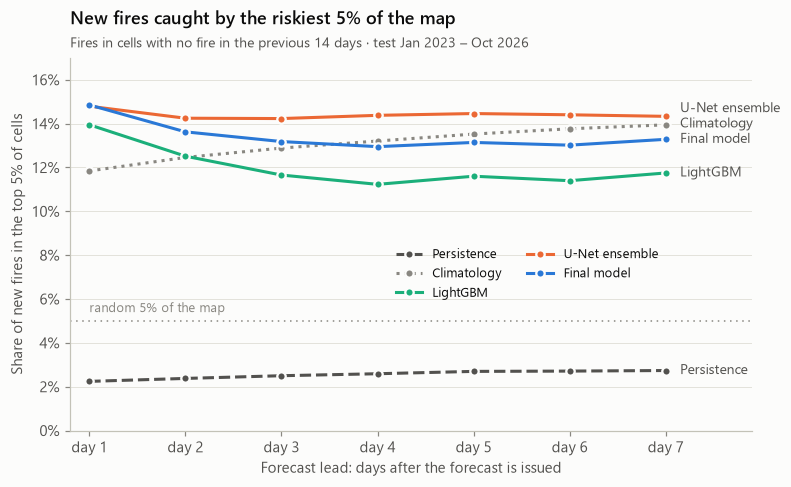

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ends = []
for m in ['persistence', 'climatology', 'lgbm', 'ens_unet', 'ens_mix']:
    color, ls = STYLE[m]
    y = curve(m, 'new_ignition', 'top5_coverage') * 100
    ax.plot(leads, y, color=color, ls=ls, marker='o', ms=5.5, mec=viz.SURFACE, mew=1.5,
            label=NAMES[m])
    ends.append((y[-1], NAMES[m]))
ax.axhline(5, color=viz.MUTED, lw=1, ls=(0, (1, 3)))
ax.text(1, 5.4, 'random 5% of the map', color=viz.MUTED, fontsize=8.5)
viz.label_ends(ax, 7.15, ends, min_gap=0.7)
ax.set_xlim(0.8, 7.9)
ax.set_ylim(0, 17)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.set_xticks(leads, [f'day {d}' for d in leads])
ax.set_xlabel('Forecast lead: days after the forecast is issued')
ax.set_ylabel('Share of new fires in the top 5% of cells')
ax.legend(loc='center right', bbox_to_anchor=(0.88, 0.42), fontsize=8.5, ncols=2)
viz.titles(ax, 'New fires caught by the riskiest 5% of the map',
           'Fires in cells with no fire in the previous 14 days · test Jan 2023 – Oct 2026')
fig.savefig(FIG / 'res_new_fires_by_lead.png')
plt.show()

## 3 · Year by year, including the 2026 El Niño season

Persistence is recomputed here from the training period exactly as in `evaluate-baselines`. 2026 covers January–October (S-NPP data ends 2 Nov 2026; Aug–Oct use the near-real-time product, see limitations).

In [5]:
fm = load_fire_matrix()
rec = recent_fire(fm.on)
start, end = (pd.Timestamp(d) for d in SPLITS['train'])
train_days = np.flatnonzero((fm.time >= start) & (fm.time <= end))
clim = Climatology().fit(fm, train_days)
pers = Persistence().fit(fm, rec, issue_days(fm, SPLITS['train']), climatology=clim)
probs = {m: np.load(MODELS_DIR / m / 'probs_test.npy', mmap_mode='r')
         for m in ['lgbm', 'ens_unet', 'ens_mix']}
years = a.time[idx].year
rows = []
for year in sorted(set(years)):
    sel = np.flatnonzero(years == year)
    for lead in (1, 7):
        y = np.asarray(a.fire_on[idx[sel] + lead])
        row = {'year': year, 'lead': lead, 'fire rate': y.mean(),
               'persistence': average_precision(y, pers.predict(idx[sel], lead))}
        for m, p in probs.items():
            row[m] = average_precision(y, np.asarray(p[sel, lead - 1], np.float32))
        rows.append(row)
by_year = pd.DataFrame(rows)
by_year.round(3)

,year,lead,fire rate,persistence,lgbm,ens_unet,ens_mix
0,2023,1,0.013,0.245,0.319,0.319,0.325
1,2023,7,0.013,0.158,0.187,0.203,0.198
2,2024,1,0.007,0.102,0.157,0.153,0.160
3,2024,7,0.007,0.052,0.061,0.075,0.069
4,2025,1,0.007,0.101,0.185,0.189,0.195
5,2025,7,0.007,0.043,0.058,0.075,0.068
6,2026,1,0.027,0.398,0.488,0.487,0.494
7,2026,7,0.028,0.293,0.349,0.362,0.362


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


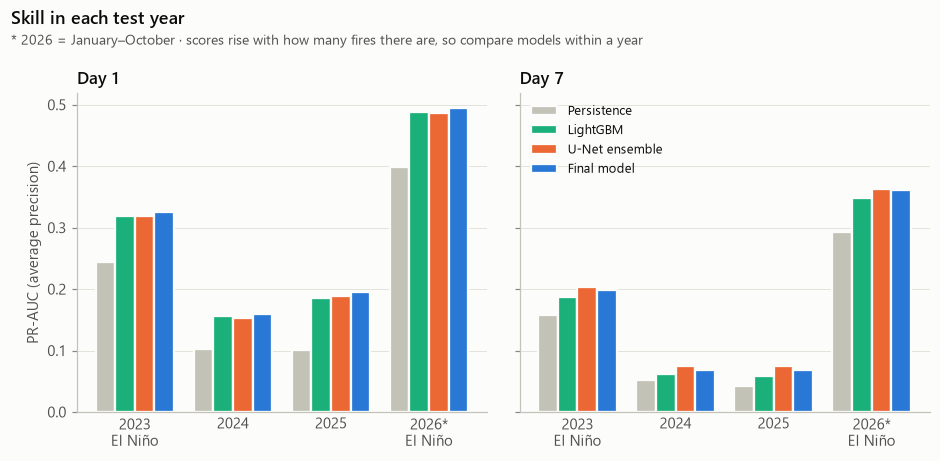

In [6]:
models = ['persistence', 'lgbm', 'ens_unet', 'ens_mix']
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
w = 0.2
for ax, lead in zip(axes, (1, 7)):
    d = by_year[by_year.lead == lead].reset_index(drop=True)
    x = np.arange(len(d))
    for i, m in enumerate(models):
        color = STYLE[m][0] if m != 'persistence' else viz.AXIS
        ax.bar(x + (i - 1.5) * w, d[m], width=w, color=color, edgecolor=viz.SURFACE,
               linewidth=1.5, label=NAMES[m])
    labels = {2023: '2023\nEl Niño', 2026: '2026*\nEl Niño'}
    ax.set_xticks(x, [labels.get(y, str(y)) for y in d.year])
    ax.tick_params(axis='x', length=0)
    ax.set_title(f'Day {lead}', fontsize=11)
axes[0].set_ylabel('PR-AUC (average precision)')
axes[1].legend(loc='upper left', fontsize=8.5)
fig.suptitle('Skill in each test year', x=0.065, ha='left', fontsize=12, fontweight='semibold')
fig.text(0.065, 0.905, '* 2026 = January–October · scores rise with how many fires there are, '
         'so compare models within a year', color=viz.INK_2, fontsize=9)
fig.subplots_adjust(top=0.8, wspace=0.08)
fig.savefig(FIG / 'res_by_year.png')
plt.show()

## 4 · Are the probabilities honest?

Each model is recalibrated on the validation years (Platt scaling per lead day). Below, the final model's forecasts are binned by predicted probability and compared with how often fires actually occurred in each bin over the test period. Points on the diagonal mean "a 10% forecast burns 10% of the time". The forecasts track the diagonal closely; at low probabilities they slightly *under*-forecast, because the test years (with two El Niño seasons) burned more than the 2021–22 years used for calibration.

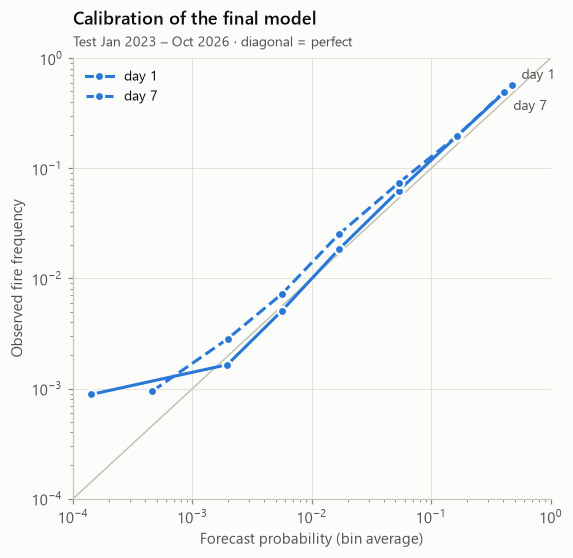

In [7]:
edges = np.array([0, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0])
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([1e-4, 1], [1e-4, 1], color=viz.AXIS, lw=1)
for lead, ls in ((1, '-'), (7, '--')):
    p = np.asarray(probs['ens_mix'][:, lead - 1], np.float32).ravel()
    y = np.asarray(a.fire_on[idx + lead]).ravel()
    b = np.digitize(p, edges[1:-1])
    mp = np.array([p[b == k].mean() for k in range(len(edges) - 1)])
    ob = np.array([y[b == k].mean() for k in range(len(edges) - 1)])
    ax.plot(mp, ob, color=STYLE['ens_mix'][0], ls=ls, marker='o', ms=6, mec=viz.SURFACE,
            mew=1.5, label=f'day {lead}')
    ax.annotate(f'day {lead}', (mp[-1], ob[-1]), xytext=(6, -12 if lead == 7 else 4),
                textcoords='offset points', color=viz.INK_2, fontsize=9)
ax.set(xscale='log', yscale='log', xlim=(1e-4, 1), ylim=(1e-4, 1))
ax.set_xlabel('Forecast probability (bin average)')
ax.set_ylabel('Observed fire frequency')
ax.grid(True, which='major', axis='both')
ax.legend(loc='upper left', fontsize=9)
viz.titles(ax, 'Calibration of the final model', 'Test Jan 2023 – Oct 2026 · diagonal = perfect')
fig.savefig(FIG / 'res_calibration.png')
plt.show()

## 5 · One forecast during the 2026 fire season

The forecast issued on **14 September 2026**, for the next day and for a week ahead. The shading is the forecast probability; blue dots are the cells where fires were actually detected on that day.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


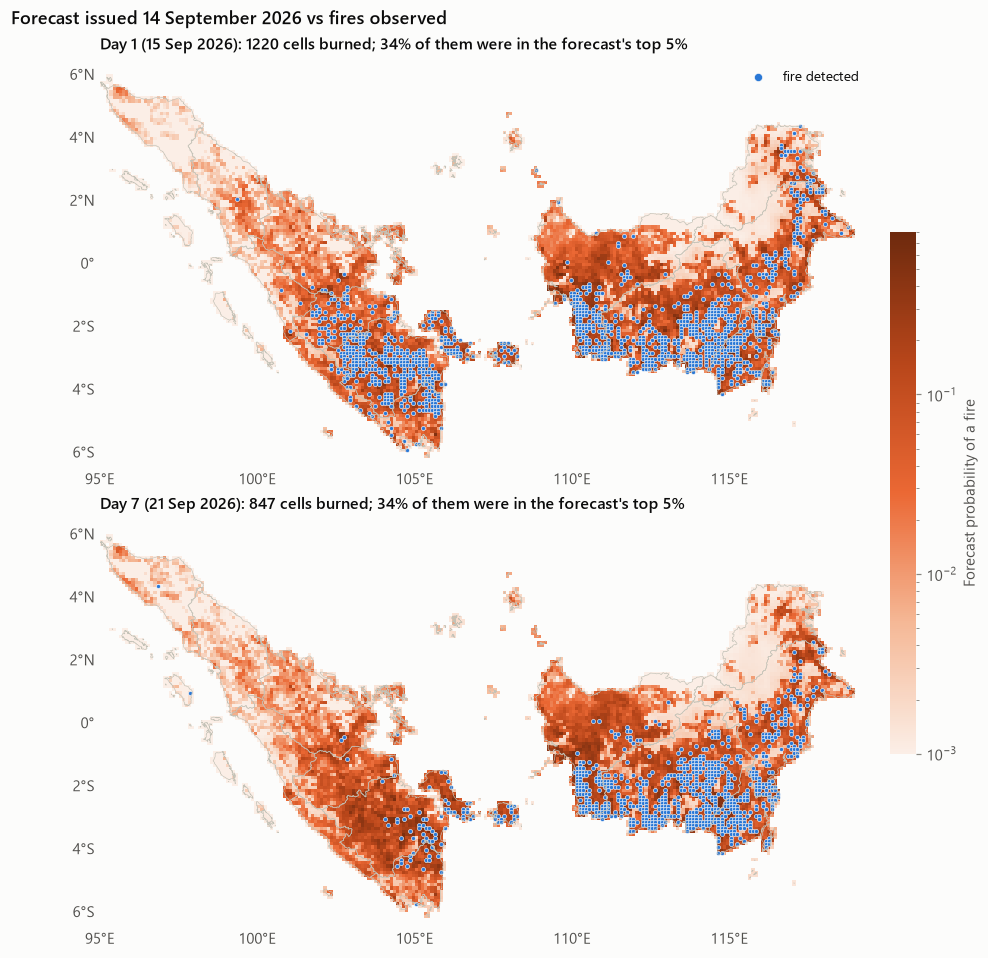

In [8]:
grid = Grid()
prov = load_provinces()
issue = pd.Timestamp('2026-09-14')
i = int(np.flatnonzero(a.time[idx] == issue)[0])
fig, axes = plt.subplots(2, 1, figsize=(9.5, 8.6), layout='constrained')
for ax, lead in zip(axes, (1, 7)):
    p = np.asarray(probs['ens_mix'][i, lead - 1], np.float32)
    y = np.asarray(a.fire_on[idx[i] + lead])
    risk = np.full(a.mask.shape, np.nan, np.float32)
    risk[a.mask] = p
    im = ax.imshow(np.ma.masked_invalid(risk), extent=viz.map_extent(grid), origin='upper',
                   cmap=viz.FIRE_CMAP, norm=LogNorm(1e-3, 0.8), interpolation='nearest')
    prov.boundary.plot(ax=ax, color=viz.AXIS, lw=0.4)
    rows, cols = np.nonzero(a.mask)
    burnt = y.astype(bool)
    ax.scatter(grid.lons[cols[burnt]], grid.lats[rows[burnt]], s=7, color=viz.BLUE,
               edgecolor=viz.SURFACE, lw=0.4, label='fire detected')
    caught = topk_coverage(y[None], p[None])
    day = (issue + pd.Timedelta(days=lead)).strftime('%d %b %Y')
    ax.set_title(f'Day {lead} ({day}): {burnt.sum()} cells burned; '
                 f'{caught:.0%} of them were in the forecast\'s top 5%', fontsize=10.5)
    ax.set_xlim(95, 119.5)
    ax.set_ylim(-6.5, 6.5)
    viz.degree_ticks(ax)
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label('Forecast probability of a fire', color=viz.INK_2)
cb.outline.set_visible(False)
axes[0].legend(loc='upper right', fontsize=9, markerscale=2)
fig.suptitle('Forecast issued 14 September 2026 vs fires observed', x=0.07, ha='left',
             fontsize=12, fontweight='semibold')
fig.savefig(FIG / 'res_example_2026-09-14.png')
plt.show()

## 6 · What drives the forecasts?

Group permutation importance (`titikapi explain`): each input group is scrambled in turn, and the drop in PR-AUC is recorded. Groups that change daily are shuffled across days; fixed map layers are shuffled across cells. The test set is sampled every 4th issue day, with 2 repeats, using one U-Net (`unet_reg`) and LightGBM on the same scrambled inputs.

**Fire history dominates day 1 for both models. At day 7, the U-Net relies on rainfall memory**: scrambling it costs a quarter of the U-Net's day-7 score, while LightGBM barely uses rain and leans on the fire climatology instead. That is the physical signal (weeks without rain make land burnable) behind the U-Net's edge at longer leads.

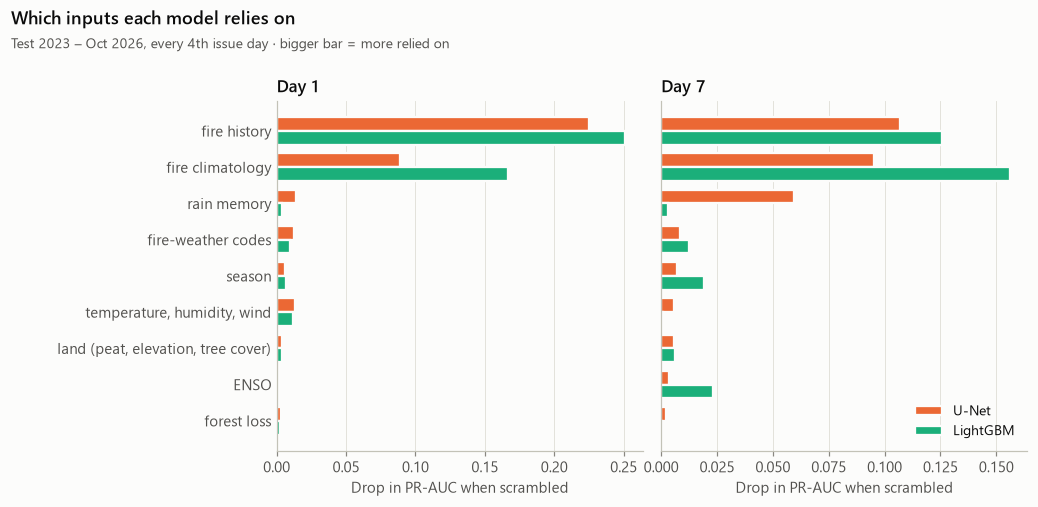

In [9]:
imp = pd.read_csv(ROOT / 'reports' / 'importance_groups.csv')
order = (imp[(imp.model == 'U-Net') & (imp.metric == 'ap_d7')]
         .sort_values('drop').group.tolist())
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
h = 0.38
for ax, metric, title in zip(axes, ('ap_d1', 'ap_d7'), ('Day 1', 'Day 7')):
    for j, (model, key) in enumerate((('U-Net', 'ens_unet'), ('LightGBM', 'lgbm'))):
        d = imp[(imp.model == model) & (imp.metric == metric)].set_index('group').reindex(order)
        y = np.arange(len(order)) + (0.5 - j) * h
        ax.barh(y, d['drop'].clip(lower=0), height=h, color=STYLE[key][0],
                edgecolor=viz.SURFACE, linewidth=1.5, label=model)
    ax.set_yticks(np.arange(len(order)), order)
    ax.set_title(title, fontsize=11)
    ax.grid(True, axis='x')
    ax.grid(False, axis='y')
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Drop in PR-AUC when scrambled')
axes[1].legend(loc='lower right', fontsize=9)
fig.suptitle('Which inputs each model relies on', x=0.02, ha='left', fontsize=12,
             fontweight='semibold')
fig.text(0.02, 0.905, 'Test 2023 – Oct 2026, every 4th issue day · bigger bar = more relied on',
         color=viz.INK_2, fontsize=9)
fig.subplots_adjust(top=0.8, wspace=0.05, left=0.25)
fig.savefig(FIG / 'res_importance.png')
plt.show()

## 7 · Validated as deployed: replaying the 2026 fire season

Live forecasts use different inputs from the test above: **NOAA-20** fire detections (S-NPP retired on 2 Nov 2026) and **ECMWF IFS** real-time weather instead of ERA5 reanalysis. `titikapi live-replay` runs the deployed code day by day over 1 Aug – 24 Oct 2026 with only those inputs. The IFS weather state is seeded from ERA5 a month earlier, then rolled forward on IFS alone. The replay scores the frozen models and tunes nothing.

In [10]:
rep = pd.read_csv(ROOT / 'reports' / 'replay.csv')
labels = {'evaluation': 'As tested: S-NPP fires + ERA5',
          'noaa20_era5': 'NOAA-20 fires + ERA5',
          'live': 'As deployed: NOAA-20 + IFS',
          'persistence_noaa20': 'Persistence (NOAA-20)'}
t = rep[rep.scenario.isin(labels) & rep.lead.isin([1, 7])]
t = t.pivot_table(index='scenario', columns='lead', values=['ap', 'top5', 'brier'])
t = t.reindex(list(labels)).rename(index=labels)
t.columns = [f'{m} day {d}' for m, d in t.columns]
t.style.format('{:.3f}')

,ap day 1,ap day 7,brier day 1,brier day 7,top5 day 1,top5 day 7
scenario,,,,,,
As tested: S-NPP fires + ERA5,0.561,0.422,0.049,0.056,0.399,0.328
NOAA-20 fires + ERA5,0.573,0.431,0.051,0.057,0.397,0.328
As deployed: NOAA-20 + IFS,0.573,0.428,0.051,0.057,0.396,0.327
Persistence (NOAA-20),0.473,0.361,0.060,0.065,0.350,0.284


Swapping ERA5 for real-time IFS weather costs **nothing measurable** (PR-AUC 0.573 → 0.573 at day 1, 0.431 → 0.428 at day 7), and the deployed system beats persistence by ~20% at the height of the season.

**Calibration shifts in an extreme season.** About 8% of land cells burned per day in Aug–Oct 2026, far above the wet 2021–22 years the probabilities were calibrated on. The ranking is unaffected, but the probabilities are *conservative*: forecasts averaging 50% verified 60% of the time at day 1. Per the project's rule (no tuning on test data), this is reported, not patched. A season-aware calibration (e.g. conditioned on ENSO) is a candidate fix, to be judged on new data via the live scorecard, which now tracks calibration too.

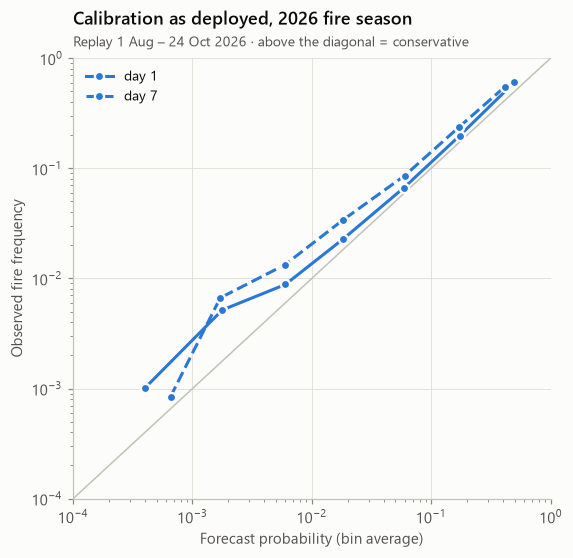

In [11]:
rel = pd.read_csv(ROOT / 'reports' / 'replay_reliability.csv')
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([1e-4, 1], [1e-4, 1], color=viz.AXIS, lw=1)
for lead, ls in ((1, '-'), (7, '--')):
    r = rel[rel.lead == lead]
    ax.plot(r.mean_forecast, r.observed, color=STYLE['ens_mix'][0], ls=ls, marker='o', ms=6,
            mec=viz.SURFACE, mew=1.5, label=f'day {lead}')
ax.set(xscale='log', yscale='log', xlim=(1e-4, 1), ylim=(1e-4, 1))
ax.set_xlabel('Forecast probability (bin average)')
ax.set_ylabel('Observed fire frequency')
ax.grid(True, which='major', axis='both')
ax.legend(loc='upper left', fontsize=9)
viz.titles(ax, 'Calibration as deployed, 2026 fire season',
           'Replay 1 Aug – 24 Oct 2026 · above the diagonal = conservative')
fig.savefig(FIG / 'res_replay_calibration.png')
plt.show()

## What this shows, and its limits

1. **Large, consistent gains over the baselines.** On 2023 to October 2026, the final model scores ~40% higher PR-AUC than persistence at both day 1 and day 7, and its riskiest 5% of cells contain 43% of next-day fires.
2. **Deep learning earns its place at longer leads and on new fires, not at day 1.** LightGBM with hand-built neighbourhood features ties the U-Net on day 1; the U-Net is better from day 2 on and is the only model that stays above climatology on new fires. Combining them gives the best overall model.
3. **Regularisation fixed overfitting but did not raise the ceiling.** A 4× smaller U-Net scores the same, so the limit is the information in the inputs, not model size.
4. **The U-Net's edge at longer leads comes from rainfall memory**, which it uses heavily and LightGBM barely uses.
5. **The deployed system (NOAA-20 + IFS) performs as tested** on a replay of the 2026 fire season.
6. **New fires a week ahead are only marginally predictable** from weather and fire history (U-Net ensemble 14.3% vs climatology 13.9%). Most are human-set; land-use pressure, accessibility and policy signals would be the next inputs to try.

**Limitations**
* *Labels are imperfect.* VIIRS misses fires under cloud and between overpasses, so some "no fire" labels are wrong, which caps achievable PR-AUC.
* *August–October 2026 use near-real-time S-NPP data*, which has no fire-type flag; detections at locations the science-quality record flags as gas flares or volcanoes were removed. NRT and SP processing differ slightly.
* *Probabilities are conservative in extreme seasons* (calibrated on wet 2021–22); ranking is unaffected.
* *Live forecasts use NOAA-20* (S-NPP stopped on 2 Nov 2026): about −5% PR-AUC at day 1 on 2023–25, no loss at day 7. Its near-real-time data has no fire-type flag; the location filter removes 97% of gas flares/volcanoes and 3% of real vegetation fires (held-out 2025).
* *No weather forecasts are used yet.* Inputs stop at the issue day; adding forecast weather for days 1–7 is the obvious next experiment.